# Assignment 4: Student Placement Classification

**Name :- Avinash Singh**
**Div:-E   Batch:-E1 Roll NO:- 312**
**PRN :- 202401040311** 

**GITHUB REPO** :- https://github.com/avinashsingh539/AIML_CA_IA_Labs/tree/main/Practical-04-Student-Placement-Classification/Practical-04-Student-Placement-Classification

**Aim:** Prepare the supplied student dataset, train four classification algorithms and compare their performance.

**Dataset:** `student_placement_dataset.csv`, supplied with the assignment. The target variable is `Placed` (Yes/No).

## 1. Import libraries

Import the libraries used for preprocessing, model training and evaluation.

In [3]:
%pip install seaborn

   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   ----- --------------------------------- 41.0/294.9 kB 393.8 kB/s eta 0:00:01
   ------------ -------------------------- 92.2/294.9 kB 655.4 kB/s eta 0:00:01
   ------------------- ------------------ 153.6/294.9 kB 762.6 kB/s eta 0:00:01
   ------------------------- ------------ 194.6/294.9 kB 787.7 kB/s eta 0:00:01
   ------------------------------------ - 286.7/294.9 kB 930.9 kB/s eta 0:00:01
   -------------------------------------- 294.9/294.9 kB 909.5 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 2. Load and inspect the dataset

Load the CSV and check its size, columns, missing values and placement distribution.

In [5]:
data_path = Path("data/student_placement_dataset.csv")
if not data_path.exists():
    raise FileNotFoundError("Run this notebook from the Assignment-04 folder.")

df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("Data Type"))
display(df.isnull().sum().to_frame("Missing Values"))
display(df["Placed"].value_counts().to_frame("Student Count"))

Dataset shape: (1200, 18)


,Student_ID,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular,Placed
0,STU1000,Male,Mechanical,85.2,75.9,7.17,2,0.0,3,1,65.0,Medium,1.8,Tier-3,Yes,7.98,No,No
1,STU1001,Male,IT,85.0,72.7,6.41,0,0.0,3,2,69.0,Low,2.5,Tier-3,No,12.46,Yes,Yes
2,STU1002,Female,Civil,79.7,85.1,7.46,1,1.0,2,0,72.0,Medium,7.3,Tier-3,Yes,5.70,No,Yes
3,STU1003,Female,Mechanical,81.6,67.0,4.51,1,1.0,0,3,63.0,Medium,20.3,Tier-2,Yes,3.68,No,No
4,STU1004,Male,Computer,70.5,78.8,8.19,0,0.0,2,0,62.0,High,3.5,Tier-1,No,18.97,Yes,Yes


,Data Type
Student_ID,object
Gender,object
Branch,object
SSC_Percentage,float64
HSC_Percentage,float64
CGPA,float64
Active_Backlogs,int64
Internships,float64
Projects,int64
Certifications,int64


,Missing Values
Student_ID,0
Gender,0
Branch,0
SSC_Percentage,0
HSC_Percentage,29
CGPA,56
Active_Backlogs,0
Internships,50
Projects,0
Certifications,0


,Student Count
Placed,
No,673
Yes,527


## 3. Data preprocessing

Remove the student ID because it is only an identifier. Fill numerical gaps with the median and categorical gaps with the most frequent value. Scale numerical features and one-hot encode categorical features.

In [6]:
X = df.drop(columns=["Placed", "Student_ID"])
y_text = df["Placed"].astype(str).str.strip()

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_text)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target classes:", list(target_encoder.classes_))
print("Missing input values:", int(X.isna().sum().sum()))

Numerical features: ['SSC_Percentage', 'HSC_Percentage', 'CGPA', 'Active_Backlogs', 'Internships', 'Projects', 'Certifications', 'Aptitude_Score', 'Coding_Hours_Per_Week', 'Family_Income_LPA']
Categorical features: ['Gender', 'Branch', 'Communication_Skill', 'City_Tier', 'Hostel_Resident', 'Extracurricular']
Target classes: ['No', 'Yes']
Missing input values: 533


## 4. Split the dataset

Use an 80:20 train-test split. Stratification keeps the placement class proportions similar in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 960
Testing records: 240


## 5. Define the classification models

All models use the same preprocessing pipeline so that the comparison is consistent.

In [8]:
models = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Decision Tree (CART)": DecisionTreeClassifier(
        criterion="gini", max_depth=5, random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}

pipelines = {
    name: Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])
    for name, model in models.items()
}

## 6. Train and evaluate

Evaluate the models on the test set. Log loss measures the quality of predicted probabilities; a lower value is better.

In [9]:
results = []
trained_models = {}
predictions = {}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1])
    })

comparison = pd.DataFrame(results).sort_values(
    "F1-Score", ascending=False
).reset_index(drop=True)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,SVM,0.7750,0.7742,0.6857,0.7273,0.4770
1,Naive Bayes,0.7458,0.7037,0.7238,0.7136,0.5423
2,Decision Tree (CART),0.7292,0.7128,0.6381,0.6734,0.7185
3,K-Nearest Neighbors,0.6958,0.6600,0.6286,0.6439,1.5583


## 7. Performance comparison

Compare accuracy, precision, recall and F1-score across the four models. The second chart compares log loss.

In [10]:
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=15
)
plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

comparison.set_index("Model")["Log Loss"].plot(
    kind="bar", figsize=(8, 4), color="darkorange"
)
plt.title("Log Loss Comparison (Lower is Better)")
plt.ylabel("Log Loss")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 1 Axes>

<Figure size 800x400 with 1 Axes>

## 8. Confusion matrices

The confusion matrices show correct and incorrect predictions for both placement classes.

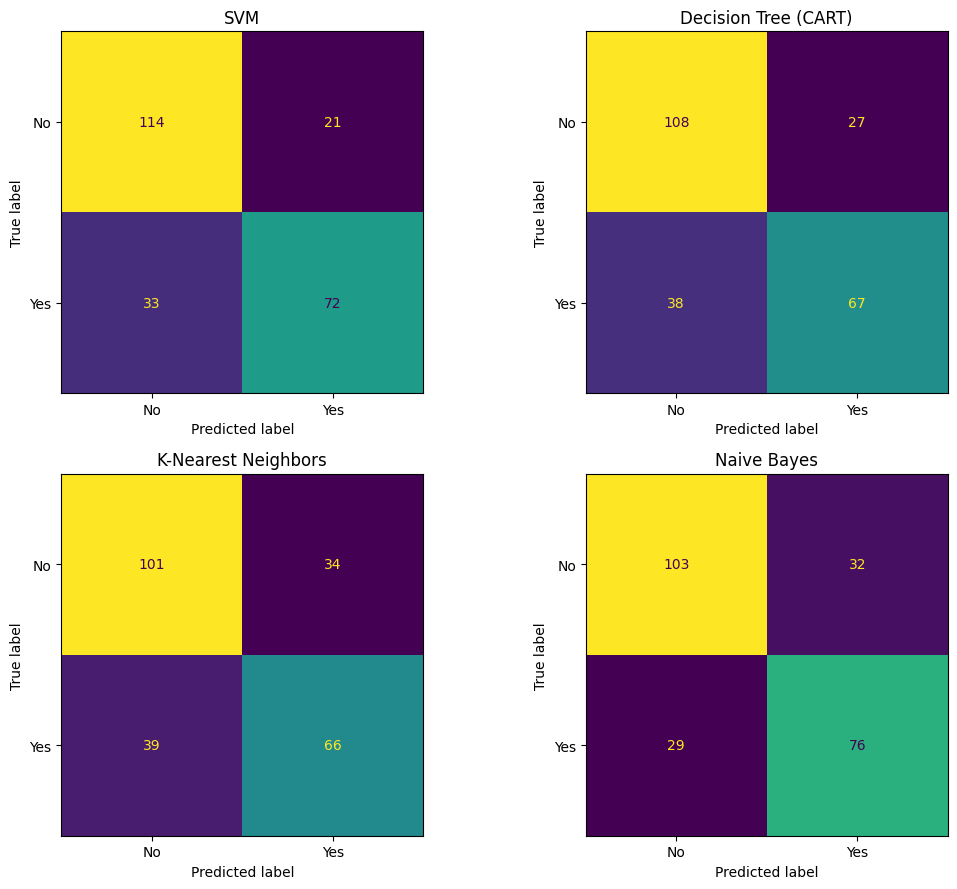

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=target_encoder.classes_
    )
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 9. Classification reports

The reports show precision, recall and F1-score for each class separately.

In [12]:
for name, y_pred in predictions.items():
    print(f"--- {name} ---")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=[str(c) for c in target_encoder.classes_],
        zero_division=0
    ))

--- SVM ---
              precision    recall  f1-score   support

          No       0.78      0.84      0.81       135
         Yes       0.77      0.69      0.73       105

    accuracy                           0.78       240
   macro avg       0.77      0.77      0.77       240
weighted avg       0.77      0.78      0.77       240

--- Decision Tree (CART) ---
              precision    recall  f1-score   support

          No       0.74      0.80      0.77       135
         Yes       0.71      0.64      0.67       105

    accuracy                           0.73       240
   macro avg       0.73      0.72      0.72       240
weighted avg       0.73      0.73      0.73       240

--- K-Nearest Neighbors ---
              precision    recall  f1-score   support

          No       0.72      0.75      0.73       135
         Yes       0.66      0.63      0.64       105

    accuracy                           0.70       240
   macro avg       0.69      0.69      0.69       240
weigh

## 10. Result and conclusion

The comparison table and charts show how SVM, CART Decision Tree, KNN and Naive Bayes perform on the supplied student placement data. Accuracy gives the overall proportion of correct predictions, while precision, recall and F1-score give a closer view of the positive placement class. Log loss evaluates the quality of predicted probabilities.

